# Project risk Monte Carlo simulation

**A learning project by Torome Caleb Saitoti.** The project, company and numbers below are invented. The aim is to show how a quantitative cost and schedule risk analysis (QCRA / QSRA) works, step by step.

**The scenario:** a made-up utility, *Northvale Grid Services*, is upgrading a 33kV substation (the *Eastvale Substation Upgrade*). The baseline estimate is **£12.0m** and **52 weeks**. A risk register lists ten things that could go wrong. The question for the project board is:

> How much contingency (extra money and time) should we hold so that we have a good chance of finishing within budget and on time?

**The idea:** a single "best guess" hides uncertainty. Instead, we run the project 10,000 times on the computer. In each run, every risk either happens or not, and if it happens, its cost and delay are drawn at random from the ranges in the register. The spread of the 10,000 results shows the range of likely outcomes.

## 1. The risk register
Each risk has a **probability** of happening, and a three-point estimate (**minimum, most likely, maximum**) for cost (£ thousands) and delay (weeks).

In [1]:
import sys
sys.path.insert(0, "../src")
import simulate as sim
import pandas as pd
pd.set_option("display.width", 200)

register = sim.load_register(sim.ROOT / "data" / "risk_register.csv")
register

,risk_id,risk,probability,cost_min_k,cost_likely_k,cost_max_k,delay_min_wks,delay_likely_wks,delay_max_wks
0,R01,Ground conditions worse than surveyed,0.30,150,400,900,2,5,12
1,R02,Late delivery of main transformer,0.25,50,200,600,3,8,20
2,R03,Planning or consent conditions cause delay,0.20,20,80,250,2,6,16
3,R04,Adverse weather during outdoor works,0.50,30,100,300,1,3,8
4,R05,Contractor resource shortage,0.30,60,250,700,2,5,12
5,R06,Design changes after approval,0.35,80,300,800,2,4,10
6,R07,Planned outage window cancelled by network operations,0.20,40,150,400,3,6,14
7,R08,Material price increases (copper and steel),0.40,100,300,900,0,1,3
8,R09,Commissioning faults or failed tests,0.25,50,200,500,2,4,10
9,R10,Health and safety incident causes a work stoppage,0.10,50,250,800,1,3,10


## 2. How one risk is sampled
If a risk happens, we need a cost between its minimum and maximum, more likely near the "most likely" value. A **triangular distribution** does that simply: it has a low point, a peak and a high point.

`triangular_inverse` converts a random number between 0 and 1 into a value from that triangle. Below, we sample risk R01 (ground conditions) 10,000 times and look at the costs *given that it happens*.

min 154, mean 484, max 893


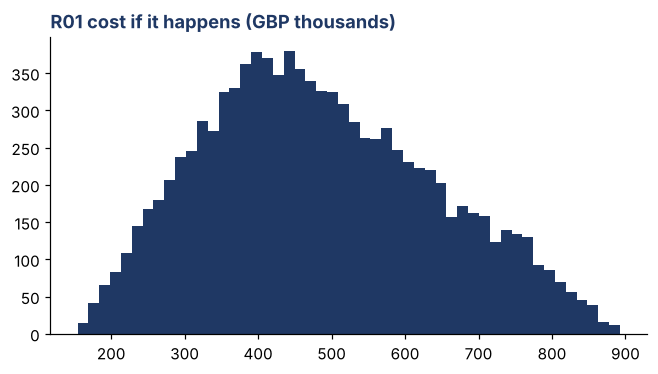

In [2]:
import numpy as np
import matplotlib.pyplot as plt

r01 = register.iloc[0]
rng = np.random.default_rng(1)
samples = sim.triangular_inverse(rng.random(10_000), r01.cost_min_k, r01.cost_likely_k, r01.cost_max_k)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(samples, bins=50, color=sim.BLUE)
ax.set_title("R01 cost if it happens (GBP thousands)", loc="left", fontweight="bold", color=sim.BLUE)
ax.spines[["top", "right"]].set_visible(False)
plt.show()
print(f"min {samples.min():.0f}, mean {samples.mean():.0f}, max {samples.max():.0f}")

## 3. Run the simulation
For each of 10,000 simulated projects:
1. Draw the baseline estimate with its own estimating uncertainty (£11.4m to £13.2m, most likely £12.0m).
2. For each risk, decide whether it happens (probability from the register).
3. If it happens, draw a cost and a delay. One random draw is used for both, so a very bad outcome is bad for cost *and* time.
4. Add everything up. For the schedule, only **60%** of each delay is assumed to reach the critical path, because some work runs in parallel. This is an assumption, and it is easy to change in `src/simulate.py`.

In [3]:
results = sim.simulate(register, n_runs=10_000, seed=42)
results[["Total cost (GBP k)", "Total duration (weeks)"]].describe().round(0)

,Total cost (GBP k),Total duration (weeks)
count,10000.0,10000.0
mean,13049.0,63.0
std,623.0,6.0
min,11433.0,48.0
25%,12599.0,58.0
50%,13016.0,62.0
75%,13467.0,67.0
max,15651.0,91.0


## 4. Percentiles and contingency
**P50** means a 50% chance of finishing at or below that value. **P80** means 80%. Many organisations set contingency at P80 (or P90 for critical projects). The contingency is the P80 value minus the baseline.

In [4]:
table = sim.percentile_table(results)
table

,measure,baseline,mean,P50,P80,P90,contingency_at_P80,chance_of_finishing_within_baseline
0,Total cost (GBP k),12000,13049.486,13016.344,13581.641,13878.465,1581.641,0.035
1,Total duration (weeks),52,62.700,62.259,67.752,70.903,15.752,0.021


### Cost distribution

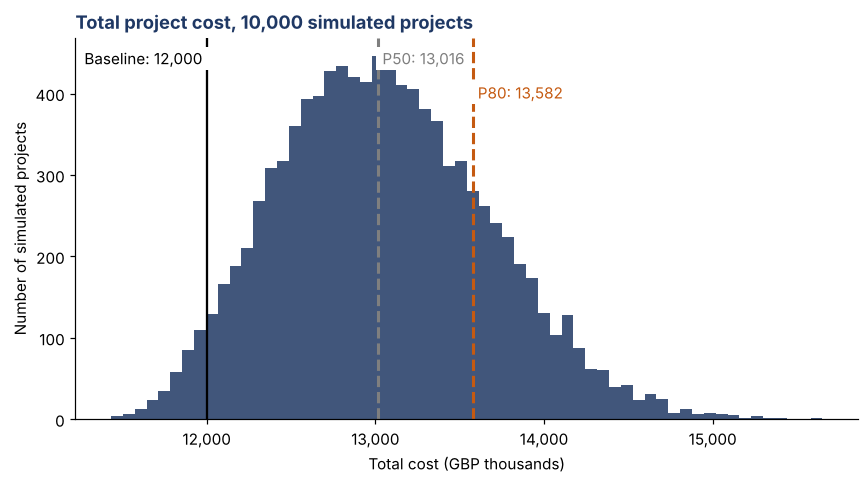

In [5]:
sim.plot_histogram(results["Total cost (GBP k)"], sim.BASELINE_COST_K,
                   "Total project cost, 10,000 simulated projects", "Total cost (GBP thousands)")
plt.show()

### Cost S-curve
The S-curve (cumulative probability) is what a project board uses to pick a confidence level: read across from 80% and down to the cost.

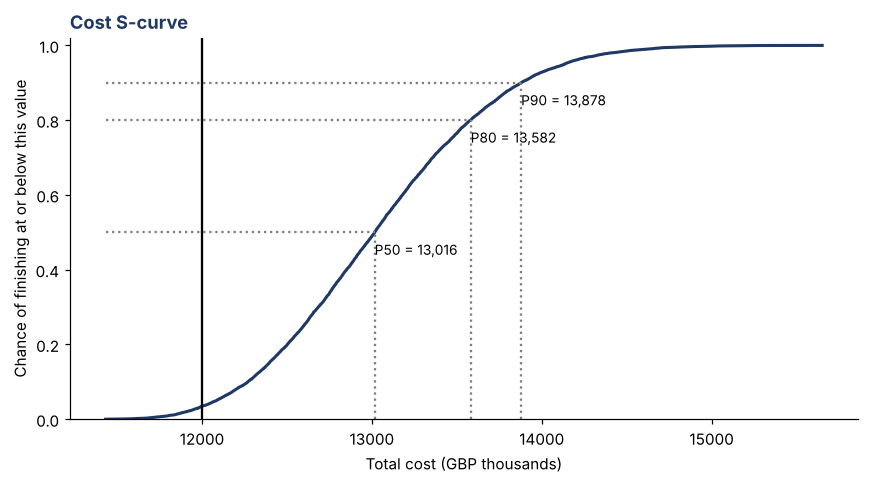

In [6]:
sim.plot_s_curve(results["Total cost (GBP k)"], sim.BASELINE_COST_K, "Cost S-curve", "Total cost (GBP thousands)")
plt.show()

### Schedule distribution

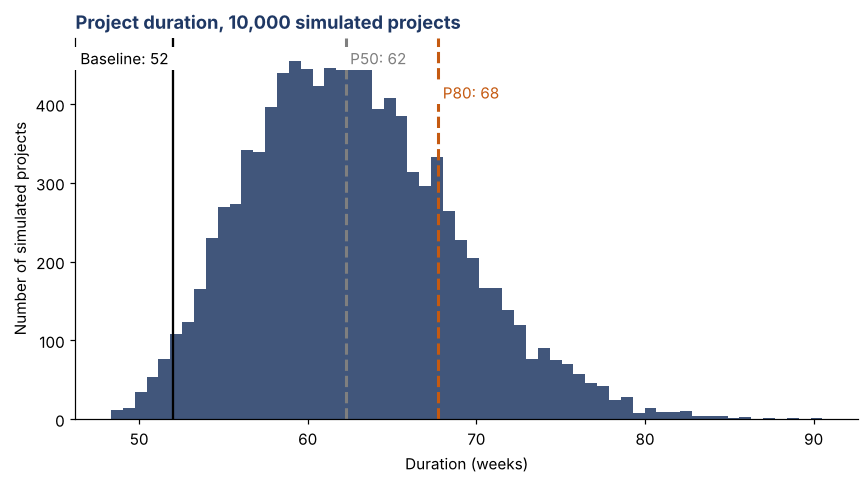

In [7]:
sim.plot_histogram(results["Total duration (weeks)"], sim.BASELINE_WEEKS,
                   "Project duration, 10,000 simulated projects", "Duration (weeks)")
plt.show()

## 5. What drives the cost?
A tornado-style chart ranks each cost driver by how strongly it moves the total (rank correlation). These are the risks to focus mitigation on first.

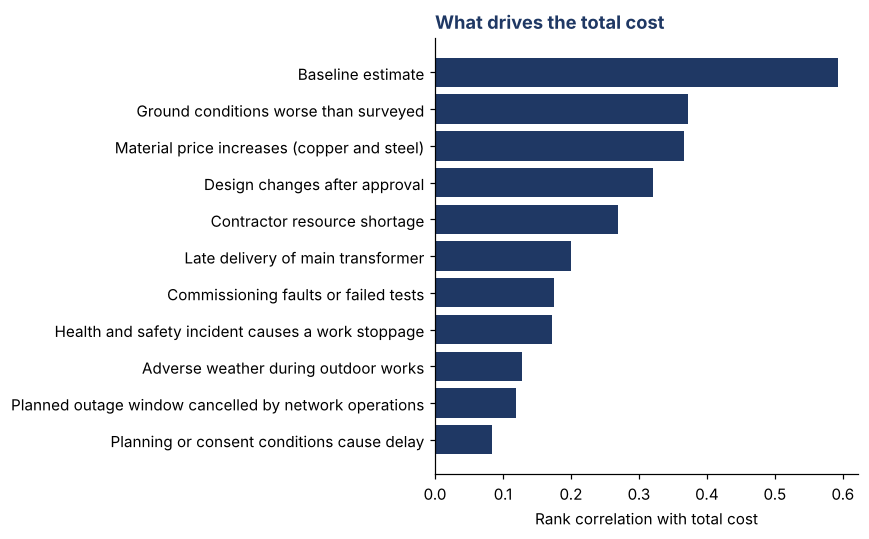

Baseline estimate                                            0.59
R01 Ground conditions worse than surveyed                    0.37
R08 Material price increases (copper and steel)              0.37
R06 Design changes after approval                            0.32
R05 Contractor resource shortage                             0.27
R02 Late delivery of main transformer                        0.20
R09 Commissioning faults or failed tests                     0.18
R10 Health and safety incident causes a work stoppage        0.17
R04 Adverse weather during outdoor works                     0.13
R07 Planned outage window cancelled by network operations    0.12
R03 Planning or consent conditions cause delay               0.08
Name: Total cost (GBP k), dtype: float64

In [8]:
drivers = sim.sensitivity(results)
sim.plot_tornado(drivers)
plt.show()
drivers.round(2)

## 6. Recommendation (calculated from the results above)

In [9]:
c, s = table.iloc[0], table.iloc[1]
top = [d.split(" ", 1)[1] for d in drivers.index if d[0] == "R"][:3]
print(f"Baseline cost: GBP {c.baseline:,.0f}k. Chance of finishing within it: {c.chance_of_finishing_within_baseline:.1%}.")
print(f"P50 cost: GBP {c.P50:,.0f}k   P80 cost: GBP {c.P80:,.0f}k   P90 cost: GBP {c.P90:,.0f}k")
print(f"Suggested cost contingency at P80: GBP {c.contingency_at_P80:,.0f}k ({c.contingency_at_P80 / c.baseline:.1%} of baseline).")
print()
print(f"Baseline duration: {s.baseline:.0f} weeks. Chance of finishing within it: {s.chance_of_finishing_within_baseline:.1%}.")
print(f"P50: {s.P50:.0f} weeks   P80: {s.P80:.0f} weeks   P90: {s.P90:.0f} weeks")
print(f"Suggested schedule contingency at P80: {s.contingency_at_P80:.0f} weeks.")
print()
print("Largest individual risk drivers of cost: " + "; ".join(top) + ".")

Baseline cost: GBP 12,000k. Chance of finishing within it: 3.5%.
P50 cost: GBP 13,016k   P80 cost: GBP 13,582k   P90 cost: GBP 13,878k
Suggested cost contingency at P80: GBP 1,582k (13.2% of baseline).

Baseline duration: 52 weeks. Chance of finishing within it: 2.1%.
P50: 62 weeks   P80: 68 weeks   P90: 71 weeks
Suggested schedule contingency at P80: 16 weeks.

Largest individual risk drivers of cost: Ground conditions worse than surveyed; Material price increases (copper and steel); Design changes after approval.


## Assumptions and limitations
- All inputs are **invented** for learning. A real analysis would use the project's own risk register and estimates agreed with the project team.
- Risks are **independent** (one happening does not make another more likely). In real projects they are often linked.
- Delays are not modelled on a real project **schedule network**. A fixed 60% of each delay is assumed to reach the critical path. Real schedule risk analysis (QSRA) uses the project programme.
- Costs and delays use a **triangular distribution**. Other distributions (for example PERT or lognormal) are common.
- Only the risks in the register are included. Unknown unknowns are not.
- Results change slightly with the random seed. The seed is fixed (42) so the notebook is reproducible.